# Маршрутизація звернень у Databricks

Досліджуємо, як Laya розподіляє звернення за категоріями і чи допомагають короткі описи. Потім перевіряємо підхід Spark ML на більшому тесті, нових намірах і перефразуваннях.

Блокнот повторює послідовність роботи. Результати завершених прогонів Databricks збережені нижче, їх можна переглянути без довгих обчислень. Для повторного запуску налаштуйте `workspace_schema`, `silver_table` та `artifact_dir` для свого Unity Catalog.


# Підготовка та перевірка даних звернень

Перевіряємо тексти й мітки, готуємо Delta-таблицю для досліду класифікації.

## Джерело даних

Відкритий набір Bitext із англомовними прикладами звернень. Перед повторним запуском задайте `workspace_schema` у першій комірці. У схемі має бути доступний Unity Catalog Volume `raw`. [Сторінка набору](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset).

In [0]:
from hashlib import sha256
from io import BytesIO
from urllib.request import urlopen
from databricks.sdk import WorkspaceClient
from pyspark.sql import functions as F

workspace_schema = "YOUR_SCHEMA"  # Set this to a writable Unity Catalog schema.
revision = "430d1a89bd93bd1fa23c16f29dd53e73f0087443"
filename = "Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv"
source_url = f"https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset/resolve/{revision}/{filename}"
raw_dir = f"/Volumes/workspace/{workspace_schema}/raw/experimental_data_ai"
raw_path = f"{raw_dir}/{filename}"
expected_sha256 = "6f81102b0100b97b8468eb04368033a23206bf1fde9d53500d5806ec1001a434"

with urlopen(source_url, timeout=60) as response:
    csv_bytes = response.read()
actual_sha256 = sha256(csv_bytes).hexdigest()
assert actual_sha256 == expected_sha256, f"Unexpected source checksum: {actual_sha256}"

dbutils.fs.mkdirs(raw_dir)
WorkspaceClient().files.upload(raw_path, BytesIO(csv_bytes), overwrite=True)
print(f"Source verified: {actual_sha256}")

Source verified: 6f81102b0100b97b8468eb04368033a23206bf1fde9d53500d5806ec1001a434


## Читання та опис даних
Spark перевіряє пропуски, повтори й узгодженість міток. Діаграма показує розподіл категорій.

Rows: 26,872 | Intents: 27 | Categories: 11
Unique messages: 24,635 | Repeated-message rows: 2,237
Exact duplicate rows: 0 | Messages with conflicting labels: 0
Intents mapped to multiple categories: 0
Missing values: {'flags': 0, 'instruction': 0, 'category': 0, 'intent': 0, 'response': 0}


category,count
ACCOUNT,5986
ORDER,3988
REFUND,2992
INVOICE,1999
CONTACT,1999
PAYMENT,1998
FEEDBACK,1997
DELIVERY,1994
SHIPPING,1970
SUBSCRIPTION,999


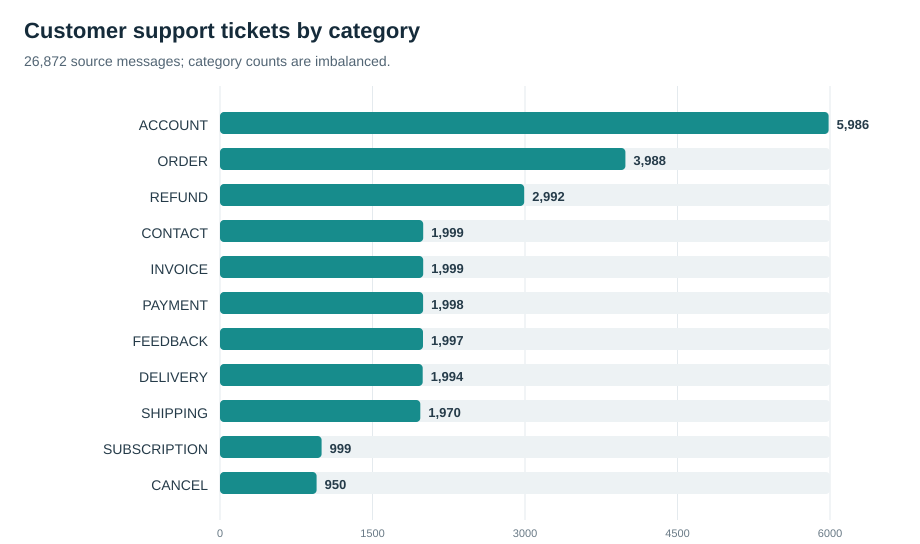

instruction,category,intent
question about cancelling order {{Order Number}},ORDER,cancel_order
i have a question about cancelling oorder {{Order Number}},ORDER,cancel_order
i need help cancelling puchase {{Order Number}},ORDER,cancel_order
I need to cancel purchase {{Order Number}},ORDER,cancel_order
"I cannot afford this order, cancel purchase {{Order Number}}",ORDER,cancel_order


In [0]:
source_df = (
    spark.read.format("csv")
    .option("header", "true")
    .option("inferSchema", "false")
    .option("multiLine", "true")
    .option("quote", '"')
    .option("escape", '"')
    .option("mode", "FAILFAST")
    .load(raw_path)
)
expected_columns = ["flags", "instruction", "category", "intent", "response"]
assert source_df.columns == expected_columns, f"Unexpected columns: {source_df.columns}"
row_count = source_df.count()
assert row_count == 26872, f"Unexpected row count: {row_count}"

missing_by_column = source_df.select(*[
    F.sum(F.when(F.col(c).isNull() | (F.trim(F.col(c)) == ""), 1).otherwise(0)).alias(c)
    for c in expected_columns
]).first().asDict()
label_conflicts = (
    source_df.groupBy("instruction")
    .agg(
        F.countDistinct("category").alias("category_labels"),
        F.countDistinct("intent").alias("intent_labels"),
    )
    .filter((F.col("category_labels") > 1) | (F.col("intent_labels") > 1))
    .count()
)
intent_category_conflicts = (
    source_df.groupBy("intent")
    .agg(F.countDistinct("category").alias("categories"))
    .filter(F.col("categories") > 1)
    .count()
)
unique_messages = source_df.select("instruction").distinct().count()
exact_duplicate_rows = row_count - source_df.dropDuplicates().count()
category_counts = source_df.groupBy("category").count().orderBy(F.desc("count"))

assert sum(missing_by_column.values()) == 0, f"Missing values found: {missing_by_column}"
print(f"Rows: {row_count:,} | Intents: {source_df.select('intent').distinct().count()} | Categories: {category_counts.count()}")
print(f"Unique messages: {unique_messages:,} | Repeated-message rows: {row_count - unique_messages:,}")
print(f"Exact duplicate rows: {exact_duplicate_rows:,} | Messages with conflicting labels: {label_conflicts}")
print(f"Intents mapped to multiple categories: {intent_category_conflicts}")
print(f"Missing values: {missing_by_column}")
display(category_counts)

from IPython.display import SVG, display


def bar_chart_svg(title, subtitle, rows, maximum, suffix=""):
    width, left, bar_width, top, row_height = 920, 220, 610, 112, 36
    height = top + row_height * len(rows) + 36
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="{title}">',
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="24" y="38" font-family="Arial,sans-serif" font-size="22" font-weight="700" fill="#152b3a">{title}</text>',
        f'<text x="24" y="66" font-family="Arial,sans-serif" font-size="14" fill="#526574">{subtitle}</text>',
    ]
    for tick in range(5):
        x = left + bar_width * tick / 4
        parts.append(f'<line x1="{x:.1f}" y1="86" x2="{x:.1f}" y2="{height-24}" stroke="#e4eaee"/>')
        parts.append(f'<text x="{x:.1f}" y="{height-7}" text-anchor="middle" font-family="Arial,sans-serif" font-size="11" fill="#687985">{maximum*tick/4:g}{suffix}</text>')
    for index, (label, value, color) in enumerate(rows):
        y = top + index * row_height
        shown = f"{value:.1f}%" if suffix == "%" else f"{value:,.0f}"
        length = max(1, bar_width * float(value) / maximum)
        parts.extend([
            f'<text x="{left-12}" y="{y+18}" text-anchor="end" font-family="Arial,sans-serif" font-size="14" fill="#253b49">{label}</text>',
            f'<rect x="{left}" y="{y}" width="{bar_width}" height="22" rx="4" fill="#edf2f4"/>',
            f'<rect x="{left}" y="{y}" width="{length:.1f}" height="22" rx="4" fill="{color}"/>',
            f'<text x="{left+length+8:.1f}" y="{y+17}" font-family="Arial,sans-serif" font-size="13" font-weight="700" fill="#253b49">{shown}</text>',
        ])
    parts.append('</svg>')
    return "\n".join(parts)


category_chart_rows = [(row["category"], row["count"], "#178c8c") for row in category_counts.orderBy(F.desc("count")).collect()]
display(SVG(bar_chart_svg(
    "Customer support tickets by category",
    "26,872 source messages; category counts are imbalanced.",
    category_chart_rows,
    maximum=6000,
)))

display(source_df.select("instruction", "category", "intent").limit(5))

## Підготовка Silver-таблиці

Очищаємо текст, зберігаємо категорії та наміри, додаємо ключ групи для поділу. Модель отримує `instruction`; поле `response` не є ознакою.

In [0]:
clean_df = source_df.select(*[F.trim(F.col(c)).alias(c) for c in expected_columns])
clean_df = (
    clean_df
    .withColumn("message_group_id", F.sha2(F.lower(F.col("instruction")), 256))
    .withColumn("source_revision", F.lit(revision))
    .withColumn("source_file_sha256", F.lit(actual_sha256))
)
silver_table = f"workspace.{workspace_schema}.support_tickets_silver"

(clean_df.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(silver_table))

silver_df = spark.table(silver_table)
silver_count = silver_df.count()
assert silver_count == row_count, f"Silver row count mismatch: {silver_count} != {row_count}"
print(f"Silver table ready | Rows: {silver_count:,}")
display(silver_df.groupBy("category").count().orderBy(F.desc("count")))

Silver table ready | Rows: 26,872


category,count
ACCOUNT,5986
ORDER,3988
REFUND,2992
INVOICE,1999
CONTACT,1999
PAYMENT,1998
FEEDBACK,1997
DELIVERY,1994
SHIPPING,1970
SUBSCRIPTION,999


In [0]:
import json

summary = {
    "source_revision": revision,
    "source_sha256": actual_sha256,
    "source_rows": row_count,
    "silver_rows": silver_count,
    "distinct_messages": unique_messages,
    "repeated_message_rows": row_count - unique_messages,
    "exact_duplicate_rows": exact_duplicate_rows,
    "messages_with_conflicting_labels": label_conflicts,
    "intents_mapped_to_multiple_categories": intent_category_conflicts,
    "missing_by_column": missing_by_column,
    "category_counts": {row["category"]: row["count"] for row in category_counts.collect()},
}
print(json.dumps(summary, ensure_ascii=False, indent=2))

## Оцінювання моделей

Підготовлену Delta-таблицю використовуємо для оцінювання Laya з назвами категорій і короткими описами.

## Етап 1. Базова модель і перший тест Laya

Спершу порівнюємо з прогнозом найчастішої категорії. Далі запускаємо готову Laya без донавчання.

# Дослідження промптів Laya

Перевіряємо готову модель на категоріях звернень. Ваги не змінюємо, порівнюємо підказки з категоріями.

## Завантаження даних

Використовуємо підготовлену Delta-таблицю. Повторні тексти залишаються в одній частині поділу.

In [ ]:
dbutils.widgets.text("silver_table", "workspace.YOUR_SCHEMA.support_tickets_silver", "Prepared Delta table")
silver_table = dbutils.widgets.get("silver_table")
print(f"Reading {silver_table}")


In [ ]:
import importlib.metadata
import torch
from pyspark.sql import functions as F

tickets = spark.table(silver_table).select("message_group_id", "instruction", "category").dropDuplicates(["message_group_id"])
train = tickets.where(F.pmod(F.xxhash64("message_group_id"), F.lit(5)) != 0)
test = tickets.where(F.pmod(F.xxhash64("message_group_id"), F.lit(5)) == 0)
labels = [row["category"] for row in train.select("category").distinct().orderBy("category").collect()]
majority_category = train.groupBy("category").count().orderBy(F.desc("count"), F.asc("category")).first()["category"]
assert train.select("message_group_id").intersect(test.select("message_group_id")).limit(1).count() == 0
print(f"Unique messages: {tickets.count():,} | Train: {train.count():,} | Held-out pool: {test.count():,}")
print(f"Categories: {len(labels)} | Базова модель: {majority_category}")
print(f"Laya: {importlib.metadata.version('laya')} | GPU available: {torch.cuda.is_available()}")


Laya: 0.4.13 | PyTorch: 2.14.1+cu130 | GPU: False
Unique groups: 24,371 | Train: 19,464 | Test: 4,907
Categories (11): ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']


## Завантаження Laya

Запуск виконується на CPU. Ваги Laya не змінюються.

In [ ]:
%pip install "laya>=0.1.6"


In [ ]:
dbutils.library.restartPython()


In [ ]:
import laya

agent = laya.load("convaiinnovations/laya", device="cpu")
questions = {
    "category": {
        "type": "choice",
        "instructions": "Which customer support category best matches the customer message? Choose one.",
        "criteria": labels,
    }
}

## Перший тест: лише назви категорій

Оцінюємо 500 відкладених звернень, потім окремо порівнюємо два промпти на тих самих 100 повідомленнях.

In [ ]:
import time

pilot_500 = test.orderBy(F.xxhash64("message_group_id")).limit(500).collect()
states_500 = [{"text": row["instruction"]} for row in pilot_500]
start = time.perf_counter()
results_500 = agent.predict_batch(states_500, questions, batch_size=16)
predictions_500 = [result["answers"]["category"]["choice"] for result in results_500]
truth_500 = [row["category"] for row in pilot_500]
laya_correct_500 = sum(pred == actual for pred, actual in zip(predictions_500, truth_500))
baseline_correct_500 = sum(majority_category == actual for actual in truth_500)

assert len(predictions_500) == len(truth_500) == 500
print(f"Unique held-out messages: {len(truth_500)} | Inference time: {time.perf_counter() - start:.1f}s")
print(f"Базова модель: {baseline_correct_500 / len(truth_500):.1%} ({baseline_correct_500}/{len(truth_500)})")
print(f"Laya: {laya_correct_500 / len(truth_500):.1%} ({laya_correct_500}/{len(truth_500)})")

Unique held-out messages: 500 | Inference time: 396.8s
Базова модель: 19.2% (96/500)
Laya: 70.2% (351/500)


## Результат першого тесту

Лише з назвами Laya правильно класифікувала 351 із 500 повідомлень, або 70,2%. Базова модель дала 96 правильних відповідей, або 19,2%. Час на CPU становив близько 397 секунд.

## Результати за категоріями

Recall показує частку правильно знайдених повідомлень кожної категорії.

In [ ]:
from collections import defaultdict

category_scores = defaultdict(lambda: [0, 0])
for actual, predicted in zip(truth_500, predictions_500):
    category_scores[actual][1] += 1
    category_scores[actual][0] += predicted == actual

print("Category | Correct / total | Recall")
for category in sorted(category_scores):
    correct, total = category_scores[category]
    print(f"{category:14} | {correct:3}/{total:<3} | {correct / total:.1%}")

Category | Correct / total | Recall
ACCOUNT        |  67/96  | 69.8%
CANCEL         |   8/22  | 36.4%
CONTACT        |  38/39  | 97.4%
DELIVERY       |  14/29  | 48.3%
FEEDBACK       |  33/45  | 73.3%
INVOICE        |  25/36  | 69.4%
ORDER          |  49/72  | 68.1%
PAYMENT        |  38/39  | 97.4%
REFUND         |  45/55  | 81.8%
SHIPPING       |  14/43  | 32.6%
SUBSCRIPTION   |  20/24  | 83.3%


## Короткі описи категорій

Описуємо типові теми категорії на основі навчальних даних. Тестові мітки не використовуємо для створення описів.

In [ ]:
from pyspark.sql import Window
from pyspark.sql import functions as F

training_intents = (
    spark.table(silver_table)
    .select("message_group_id", "category", "intent")
    .dropDuplicates(["message_group_id"])
    .where(F.pmod(F.xxhash64("message_group_id"), F.lit(5)) != 0)
    .groupBy("category", "intent")
    .count()
)
rank_by_category = Window.partitionBy("category").orderBy(F.desc("count"), F.asc("intent"))
intent_examples = (
    training_intents
    .withColumn("rank", F.row_number().over(rank_by_category))
    .where(F.col("rank") <= 5)
    .orderBy("category", "rank")
)
display(intent_examples)

category,intent,count,rank
ACCOUNT,recover_password,824,1
ACCOUNT,registration_problems,790,2
ACCOUNT,delete_account,718,3
ACCOUNT,create_account,714,4
ACCOUNT,switch_account,700,5
CANCEL,check_cancellation_fee,734,1
CONTACT,contact_customer_service,793,1
CONTACT,contact_human_agent,784,2
DELIVERY,delivery_period,798,1
DELIVERY,delivery_options,525,2


In [ ]:
category_descriptions = {
    "ACCOUNT": "account login, password recovery, registration, and account management",
    "CANCEL": "questions about cancellation fees or cancellation policies",
    "CONTACT": "contact customer service or speak with a human agent",
    "DELIVERY": "delivery timeframes and available delivery options",
    "FEEDBACK": "complaints, reviews, and customer feedback",
    "INVOICE": "checking or obtaining an invoice",
    "ORDER": "placing, changing, tracking, or cancelling an order",
    "PAYMENT": "payment problems and payment methods",
    "REFUND": "refund policies, refund requests, and refund status",
    "SHIPPING": "setting up or changing a shipping address",
    "SUBSCRIPTION": "newsletter subscription questions",
}
assert set(category_descriptions) == set(labels)
described_questions = {
    "category": {
        "type": "choice",
        "instructions": "Choose the support category that best matches the customer message.",
        "criteria": category_descriptions,
    }
}
print(f"Defined descriptions for {len(category_descriptions)} categories.")

Defined descriptions for 11 categories.


## Парний тест промптів

Беремо 100 інших повідомлень і оцінюємо їх обома промптами. Вибірка в обох випадках однакова.

In [ ]:
used_test_ids = [row["message_group_id"] for row in pilot_500]
fresh_pilot = (
    test.where(~F.col("message_group_id").isin(used_test_ids))
    .orderBy(F.xxhash64("message_group_id"))
    .limit(100)
    .collect()
)
assert len(fresh_pilot) == 100
assert not (set(used_test_ids) & {row["message_group_id"] for row in fresh_pilot})
states_fresh = [{"text": row["instruction"]} for row in fresh_pilot]
truth_fresh = [row["category"] for row in fresh_pilot]

start = time.perf_counter()
original_results_fresh = agent.predict_batch(states_fresh, questions, batch_size=16)
described_results_fresh = agent.predict_batch(states_fresh, described_questions, batch_size=16)
original_predictions_fresh = [r["answers"]["category"]["choice"] for r in original_results_fresh]
described_predictions_fresh = [r["answers"]["category"]["choice"] for r in described_results_fresh]
original_correct = sum(p == y for p, y in zip(original_predictions_fresh, truth_fresh))
described_correct = sum(p == y for p, y in zip(described_predictions_fresh, truth_fresh))
fixed = sum(old != y and new == y for old, new, y in zip(original_predictions_fresh, described_predictions_fresh, truth_fresh))
new_errors = sum(old == y and new != y for old, new, y in zip(original_predictions_fresh, described_predictions_fresh, truth_fresh))
baseline_correct_fresh = sum(majority_category == y for y in truth_fresh)

assert len(original_predictions_fresh) == len(described_predictions_fresh) == len(truth_fresh) == 100
print(f"Fresh held-out messages: {len(truth_fresh)} | Paired inference time: {time.perf_counter() - start:.1f}s")
print(f"Базова модель: {baseline_correct_fresh / 100:.1%} ({baseline_correct_fresh}/100)")
print(f"Labels only: {original_correct / 100:.1%} ({original_correct}/100)")
print(f"With descriptions: {described_correct / 100:.1%} ({described_correct}/100)")
print(f"Errors fixed: {fixed} | Correct answers changed to errors: {new_errors}")

Fresh held-out messages: 100 | Paired inference time: 245.1s
Базова модель: 19.0% (19/100)
Labels only: 60.0% (60/100)
With descriptions: 91.0% (91/100)
Errors fixed: 33 | Correct answers changed to errors: 2


## Результат парного тесту

Описи виправили 33 помилки та додали 2. Обидві версії бачили однакові повідомлення.

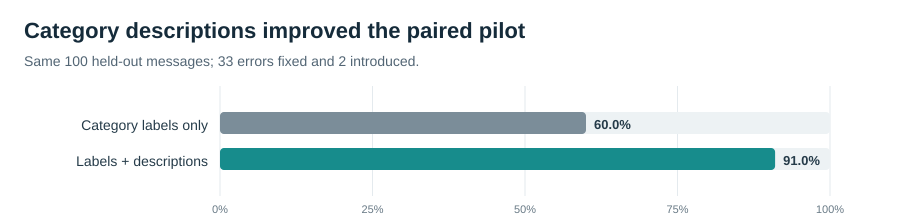

In [ ]:
pilot_rows = [
    ("Category labels only", original_correct / 100 * 100, "#7b8d99"),
    ("Labels + descriptions", described_correct / 100 * 100, "#178c8c"),
]
display(SVG(bar_chart_svg(
    "Category descriptions improved the paired pilot",
    f"Same 100 held-out messages; {fixed} errors fixed and {new_errors} introduced.",
    pilot_rows,
    maximum=100,
    suffix="%",
)))


## Нова вибірка для перевірки

Окремо оцінюємо описи на ще 500 повідомленнях, не використаних у двох попередніх тестах.

In [ ]:
from pyspark.sql import functions as F
import time

used_ids = [row["message_group_id"] for row in pilot_500]
fresh_100 = test.where(~F.col("message_group_id").isin(used_ids)).orderBy(F.xxhash64("message_group_id")).limit(100).collect()
used_ids += [row["message_group_id"] for row in fresh_100]
validation_500 = test.where(~F.col("message_group_id").isin(used_ids)).orderBy(F.xxhash64("message_group_id")).limit(500).collect()

assert len(validation_500) == 500
assert not (set(used_ids) & {row["message_group_id"] for row in validation_500})
assert set(category_descriptions) == set(labels)
assert len({row["message_group_id"] for row in validation_500}) == 500

states_validation = [{"text": row["instruction"]} for row in validation_500]
start = time.perf_counter()
results_validation = agent.predict_batch(states_validation, described_questions, batch_size=16)
predictions_validation = [result["answers"]["category"]["choice"] for result in results_validation]
truth_validation = [row["category"] for row in validation_500]
correct_validation = sum(pred == actual for pred, actual in zip(predictions_validation, truth_validation))
baseline_validation = sum(majority_category == actual for actual in truth_validation)
assert len(predictions_validation) == len(truth_validation) == 500

print(f"Fresh held-out groups: {len(validation_500)} | Inference: {time.perf_counter() - start:.1f}s")
print(f"Базова модель: {baseline_validation/500:.1%} ({baseline_validation}/500)")
print(f"Laya with category descriptions: {correct_validation/500:.1%} ({correct_validation}/500)")

Fresh held-out groups: 500 | Inference: 839.6s
Базова модель: 21.8% (109/500)
Laya with category descriptions: 93.8% (469/500)


In [ ]:
from collections import Counter

assert len(predictions_validation) == len(truth_validation) == 500
assert all(prediction in labels for prediction in predictions_validation)
true_positive = Counter(actual for actual, predicted in zip(truth_validation, predictions_validation) if actual == predicted)
actual_count = Counter(truth_validation)
predicted_count = Counter(predictions_validation)

print("Category       | Support | Recall | Precision")
for label in labels:
    tp = true_positive[label]
    print(f"{label:14} | {actual_count[label]:7} | {tp/actual_count[label]:.1%} | {tp/predicted_count[label]:.1%}")

confusions = Counter((actual, predicted) for actual, predicted in zip(truth_validation, predictions_validation) if actual != predicted)
print("\nMost common errors:")
for (actual, predicted), count in confusions.most_common(8):
    print(f"{actual} → {predicted}: {count}")

Category       | Support | Recall | Precision
ACCOUNT        |     109 | 86.2% | 100.0%
CANCEL         |      18 | 94.4% | 68.0%
CONTACT        |      39 | 100.0% | 97.5%
DELIVERY       |      29 | 96.6% | 96.6%
FEEDBACK       |      33 | 93.9% | 96.9%
INVOICE        |      32 | 100.0% | 97.0%
ORDER          |      66 | 90.9% | 96.8%
PAYMENT        |      46 | 100.0% | 95.8%
REFUND         |      52 | 94.2% | 98.0%
SHIPPING       |      52 | 94.2% | 98.0%
SUBSCRIPTION   |      24 | 100.0% | 64.9%

Most common errors:
ACCOUNT → CANCEL: 7
ACCOUNT → SUBSCRIPTION: 7
ORDER → SUBSCRIPTION: 6
REFUND → PAYMENT: 2
FEEDBACK → CANCEL: 1
SHIPPING → FEEDBACK: 1
DELIVERY → SHIPPING: 1
SHIPPING → CONTACT: 1


In [ ]:
print("Most common confusion pairs (true → predicted):")
for (pair, count) in confusions.most_common(8):
    print(f"{pair[0]} → {pair[1]}: {count}")
print(f"\nTotal errors: {sum(confusions.values())}")

Most common confusion pairs (true → predicted):
ACCOUNT → CANCEL: 7
ACCOUNT → SUBSCRIPTION: 7
ORDER → SUBSCRIPTION: 6
REFUND → PAYMENT: 2
FEEDBACK → CANCEL: 1
SHIPPING → FEEDBACK: 1
DELIVERY → SHIPPING: 1
SHIPPING → CONTACT: 1

Total errors: 31


## Що показали помилки

Laya правильно класифікувала 469 із 500 повідомлень. Часті плутанини були між ACCOUNT, CANCEL і SUBSCRIPTION.

approach,accuracy_percent
Базова модель,21.8
Laya з описами,93.8


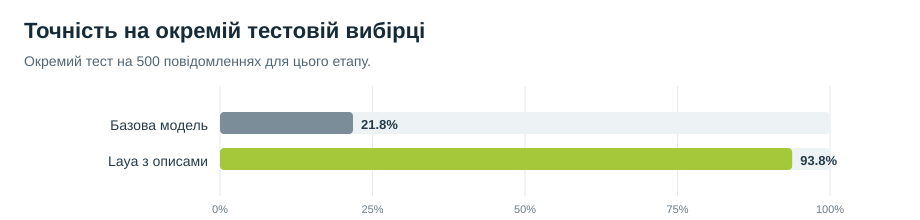

In [ ]:
assert baseline_validation == 109 and correct_validation == 469

evaluation_comparison = spark.createDataFrame(
    [("Базова модель", baseline_validation), ("Laya з описами", correct_validation)],
    ["approach", "correct"],
).withColumn("accuracy_percent", F.round(F.col("correct") / F.lit(500) * 100, 1))
display(evaluation_comparison.select("approach", "accuracy_percent"))

accuracy_rows = [
    (row["approach"], float(row["accuracy_percent"]), "#7b8d99" if row["approach"] == "Базова модель" else "#a5c83b")
    for row in evaluation_comparison.collect()
]
display(SVG(bar_chart_svg(
    "Точність на окремій тестовій вибірці",
    "Окремий тест на 500 повідомленнях для цього етапу.",
    accuracy_rows,
    maximum=100,
    suffix="%",
)))


## Етап 2. Перша модель Spark ML

Нижче збережений початковий Spark ML прогін. Після нього поділ було посилено: згруповано шаблони з номерами, а основні метрики перераховано на новій спільній тестовій вибірці. Старі значення позначені як попередній прогін.

# Навчання й оцінювання класифікатора звернень

Навчаємо текстовий класифікатор Spark ML, порівнюємо з базовою моделлю та окремо перевіряємо нові наміри.

## Поділ без повторів

Беремо один рядок на групу нормалізованих повідомлень. Однакові тексти не переходять між частинами.

In [ ]:
if "silver_table" not in dbutils.widgets.getAll():
    dbutils.widgets.text("silver_table", "workspace.YOUR_SCHEMA.support_tickets_silver", "Silver table")
silver_table = dbutils.widgets.get("silver_table")

from pyspark.sql import functions as F

tickets = (
    spark.table(silver_table)
    .select("message_group_id", "instruction", "category", "intent")
    .dropDuplicates(["message_group_id"])
)
train = tickets.where(F.pmod(F.xxhash64("message_group_id"), F.lit(5)) != 0)
test = tickets.where(F.pmod(F.xxhash64("message_group_id"), F.lit(5)) == 0)

assert train.select("message_group_id").join(test.select("message_group_id"), "message_group_id").count() == 0
assert train.select("category").distinct().count() == test.select("category").distinct().count()
assert tickets.count() == 24371 and train.count() == 19464 and test.count() == 4907

majority_category = train.groupBy("category").count().orderBy(F.desc("count"), F.asc("category")).first()["category"]
print(f"Unique messages: {tickets.count():,} | Train: {train.count():,} | Test: {test.count():,}")
print(f"Majority-category baseline: {majority_category}")


Unique messages: 24,371 | Train: 19,464 | Test: 4,907
Majority-category baseline: ACCOUNT


## Навчання Spark ML

Пайплайн токенізує текст, створює TF-IDF ознаки та навчає логістичну регресію. Параметр регуляризації вибираємо на валідаційних даних.

In [ ]:
import time
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.feature import HashingTF, IDF, IndexToString, RegexTokenizer, StringIndexer

tokenizer = RegexTokenizer(inputCol="instruction", outputCol="tokens", pattern="\\W+", toLowercase=True)
hashing = HashingTF(inputCol="tokens", outputCol="raw_features", numFeatures=1 << 18)
idf = IDF(inputCol="raw_features", outputCol="features")
indexer = StringIndexer(inputCol="category", outputCol="label", handleInvalid="error")
classifier = LogisticRegression(labelCol="label", featuresCol="features", maxIter=100)
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
regularization_values = [0.01, 0.1, 1.0]
train_with_fold = train.withColumn("cv_fold", F.pmod(F.xxhash64("message_group_id"), F.lit(3)))

started = time.perf_counter()
cv_rows = []
for reg_param in regularization_values:
    fold_scores = []
    for fold in range(3):
        fold_train = train_with_fold.where(F.col("cv_fold") != fold).drop("cv_fold")
        fold_validation = train_with_fold.where(F.col("cv_fold") == fold).drop("cv_fold")
        fold_pipeline = Pipeline(stages=[
            tokenizer, hashing, idf, indexer,
            LogisticRegression(labelCol="label", featuresCol="features", maxIter=100, regParam=reg_param),
        ])
        fold_model = fold_pipeline.fit(fold_train)
        fold_score = evaluator.evaluate(fold_model.transform(fold_validation))
        fold_scores.append(float(fold_score))
    cv_rows.append((float(reg_param), float(sum(fold_scores) / len(fold_scores))))
best_reg_param, best_cv_f1 = max(cv_rows, key=lambda row: row[1])
final_pipeline = Pipeline(stages=[
    tokenizer, hashing, idf, indexer,
    LogisticRegression(labelCol="label", featuresCol="features", maxIter=100, regParam=best_reg_param),
])
best_pipeline = final_pipeline.fit(train)
training_seconds = time.perf_counter() - started

display(spark.createDataFrame(cv_rows, "reg_param DOUBLE, mean_cv_weighted_f1 DOUBLE").orderBy("reg_param"))
print(f"Selected regularization: {best_reg_param:g}")
print(f"Best 3-fold validation weighted F1: {best_cv_f1:.3f}")
print(f"Distributed Spark ML training and tuning: {training_seconds:.1f} seconds")


reg_param,mean_cv_weighted_f1
0.01,0.9976868067697824
0.1,0.997276643328732
1.0,0.9559002054531621


Selected regularization: 0.01
Best 3-fold validation weighted F1: 0.998
Distributed Spark ML training and tuning: 218.0 seconds


## Оцінювання на відкладених повідомленнях

Порівнюємо точність і F1 з базовою моделлю. Macro F1 надає однакову вагу кожній категорії.

In [ ]:
def add_category_prediction(frame, fitted_pipeline):
    scored = fitted_pipeline.transform(frame)
    labels = fitted_pipeline.stages[-2].labels
    return IndexToString(inputCol="prediction", outputCol="predicted_category", labels=labels).transform(scored)

def summarize_predictions(frame, actual_col="category", predicted_col="predicted_category"):
    pairs = frame.groupBy(actual_col, predicted_col).count().collect()
    counts = {(row[actual_col], row[predicted_col]): row["count"] for row in pairs}
    labels = sorted({row[actual_col] for row in pairs} | {row[predicted_col] for row in pairs})
    total = sum(counts.values())
    stats = []
    for label in labels:
        tp = counts.get((label, label), 0)
        support = sum(count for (actual, _), count in counts.items() if actual == label)
        predicted = sum(count for (_, guess), count in counts.items() if guess == label)
        precision = tp / predicted if predicted else 0.0
        recall = tp / support if support else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        stats.append((label, support, precision, recall, f1))
    accuracy = sum(counts.get((label, label), 0) for label in labels) / total
    macro_f1 = sum(row[4] for row in stats) / len(stats)
    weighted_f1 = sum(row[1] * row[4] for row in stats) / total
    return accuracy, macro_f1, weighted_f1, stats

test_scored = add_category_prediction(test, best_pipeline)
model_accuracy, model_macro_f1, model_weighted_f1, category_stats = summarize_predictions(test_scored)
baseline_scored = test.withColumn("predicted_category", F.lit(majority_category))
baseline_accuracy, baseline_macro_f1, baseline_weighted_f1, _ = summarize_predictions(baseline_scored)

assert test_scored.count() == 4907
assert 0 <= model_accuracy <= 1 and 0 <= model_macro_f1 <= 1
display(spark.createDataFrame([
    ("Majority baseline", 4907, baseline_accuracy, baseline_macro_f1, baseline_weighted_f1),
    ("Spark TF-IDF + Logistic Regression", 4907, model_accuracy, model_macro_f1, model_weighted_f1),
], "approach STRING, test_messages INT, accuracy DOUBLE, macro_f1 DOUBLE, weighted_f1 DOUBLE"))
display(spark.createDataFrame(
    [(str(label), int(support), float(precision), float(recall), float(f1)) for label, support, precision, recall, f1 in category_stats],
    "category STRING, messages INT, precision DOUBLE, recall DOUBLE, f1 DOUBLE",
).orderBy("recall"))
print(f"Spark ML test: {model_accuracy:.1%} accuracy | {model_macro_f1:.3f} macro F1 | {model_weighted_f1:.3f} weighted F1")
print(f"Majority baseline: {baseline_accuracy:.1%} accuracy")


approach,test_messages,accuracy,macro_f1,weighted_f1
Majority baseline,4907,0.20949663745669453,0.03149268591560083,0.07257372984177995
Spark TF-IDF + Logistic Regression,4907,0.9991848379865498,0.9991292710065565,0.9991843329543733


category,messages,precision,recall,f1
PAYMENT,387,1.0,0.9948320413436692,0.9974093264248705
SUBSCRIPTION,215,1.0,0.9953488372093023,0.9976689976689977
DELIVERY,326,1.0,0.9969325153374233,0.9984639016897081
ACCOUNT,1028,0.9980582524271845,1.0,0.9990281827016522
CANCEL,208,1.0,1.0,1.0
CONTACT,395,1.0,1.0,1.0
FEEDBACK,434,1.0,1.0,1.0
INVOICE,354,1.0,1.0,1.0
ORDER,625,1.0,1.0,1.0
REFUND,502,0.9980119284294234,1.0,0.999004975124378


Spark ML test: 99.9% accuracy | 0.999 macro F1 | 0.999 weighted F1
Базова модель: 20.9% accuracy


## Порівняння моделей

Цей історичний фрагмент не використовує узгоджену вибірку Laya й Spark. Не трактуйте його як пряме порівняння. Основний аналіз дивіться в розділі посиленого оцінювання нижче.

## Перевірка нових намірів

Вилучаємо окремі наміри з навчання та оцінюємо модель на повідомленнях із цих тем.

In [ ]:
from hashlib import sha256

intent_rows = tickets.select("category", "intent").distinct().collect()
by_category = {}
for row in intent_rows:
    by_category.setdefault(row["category"], []).append(row["intent"])
heldout_intents = {
    min(intents, key=lambda intent: sha256(f"{category}|{intent}".encode()).hexdigest())
    for category, intents in by_category.items() if len(intents) > 1
}
intent_train = tickets.where(~F.col("intent").isin(sorted(heldout_intents)))
intent_test = tickets.where(F.col("intent").isin(sorted(heldout_intents)))
assert len(heldout_intents) == 9
assert intent_train.select("intent").distinct().join(intent_test.select("intent").distinct(), "intent").count() == 0

intent_pipeline = Pipeline(stages=[
    tokenizer, hashing, idf, indexer,
    LogisticRegression(labelCol="label", featuresCol="features", maxIter=100, regParam=best_reg_param),
])
intent_model = intent_pipeline.fit(intent_train)
intent_scored = add_category_prediction(intent_test, intent_model)
intent_accuracy, intent_macro_f1, intent_weighted_f1, intent_category_stats = summarize_predictions(intent_scored)
intent_majority = intent_train.groupBy("category").count().orderBy(F.desc("count"), F.asc("category")).first()["category"]
intent_baseline = intent_test.withColumn("predicted_category", F.lit(intent_majority))
intent_baseline_accuracy, intent_baseline_macro_f1, intent_baseline_weighted_f1, _ = summarize_predictions(intent_baseline)
intent_count = intent_test.count()
assert intent_count == 8443
display(spark.createDataFrame([
    ("Majority baseline", intent_count, intent_baseline_accuracy, intent_baseline_macro_f1, intent_baseline_weighted_f1),
    ("Spark TF-IDF + Logistic Regression", intent_count, intent_accuracy, intent_macro_f1, intent_weighted_f1),
], "approach STRING, test_messages INT, accuracy DOUBLE, macro_f1 DOUBLE, weighted_f1 DOUBLE"))
display(spark.createDataFrame(
    [(str(label), int(support), float(precision), float(recall), float(f1)) for label, support, precision, recall, f1 in intent_category_stats],
    "category STRING, messages INT, precision DOUBLE, recall DOUBLE, f1 DOUBLE",
).orderBy("recall"))
print(f"Unseen intents: {len(heldout_intents)} | Train: {intent_train.count():,} | Test: {intent_count:,}")
print(f"Unseen-intent test: {intent_accuracy:.1%} accuracy | {intent_macro_f1:.3f} macro F1")
print(f"Majority baseline: {intent_baseline_accuracy:.1%} accuracy")


approach,test_messages,accuracy,macro_f1,weighted_f1
Majority baseline,8443,0.11773066445576218,0.023406685269565426,0.024801161485435545
Spark TF-IDF + Logistic Regression,8443,0.6225275376051167,0.49387774598046996,0.6061786660948583


category,messages,precision,recall,f1
CANCEL,0,0.0,0.0,0.0
SUBSCRIPTION,0,0.0,0.0,0.0
FEEDBACK,999,0.4222222222222222,0.01901901901901902,0.03639846743295019
ACCOUNT,994,0.06828057107386716,0.11066398390342053,0.08445297504798464
DELIVERY,657,0.9620253164556962,0.2313546423135464,0.3730061349693251
ORDER,993,0.9331395348837209,0.6465256797583081,0.7638310529446759
CONTACT,983,0.6975190839694656,0.7436419125127162,0.7198424421467258
REFUND,916,0.9054545454545454,0.8155021834061136,0.8581275129236071
PAYMENT,995,0.535,0.9678391959798995,0.689087656529517
SHIPPING,992,0.8421955403087479,0.9899193548387096,0.9101019462465245


Unseen intents: 9 | Train: 15,928 | Test: 8,443
Unseen-intent test: 62.3% accuracy | 0.494 macro F1
Базова модель: 11.8% accuracy


## Збереження результатів

Прогнози та метрики зберігаємо у Delta для перегляду в Databricks SQL.

In [ ]:
prediction_table = silver_table.rsplit(".", 1)[0] + ".support_ticket_routing_predictions"
(test_scored.select("message_group_id", F.col("category").alias("actual_category"), "predicted_category")
 .withColumn("model", F.lit("spark_ml_tfidf_logistic_regression"))
 .write.format("delta").mode("overwrite").saveAsTable(prediction_table))
assert spark.table(prediction_table).count() == 4907
display(spark.table(prediction_table).where(F.col("actual_category") != F.col("predicted_category"))
        .groupBy("actual_category", "predicted_category").count().orderBy(F.desc("count")).limit(10))

intent_prediction_table = silver_table.rsplit(".", 1)[0] + ".support_ticket_unseen_intent_predictions"
(intent_scored.select("message_group_id", "intent", F.col("category").alias("actual_category"), "predicted_category")
 .write.format("delta").mode("overwrite").saveAsTable(intent_prediction_table))
assert spark.table(intent_prediction_table).count() == intent_count

metric_rows = [
    ("unique_messages", 24371.0), ("train_messages", 19464.0), ("test_messages", 4907.0),
    ("selected_reg_param", best_reg_param), ("cv_best_weighted_f1", best_cv_f1),
    ("training_seconds", float(training_seconds)), ("test_accuracy", model_accuracy),
    ("test_macro_f1", model_macro_f1), ("test_weighted_f1", model_weighted_f1),
    ("test_baseline_accuracy", baseline_accuracy), ("shared_500_model_accuracy", shared_accuracy),
    ("shared_500_laya_accuracy", 0.938), ("unseen_intent_count", float(len(heldout_intents))),
    ("unseen_intent_messages", float(intent_count)), ("unseen_intent_accuracy", intent_accuracy),
    ("unseen_intent_macro_f1", intent_macro_f1), ("unseen_intent_baseline_accuracy", intent_baseline_accuracy),
]
metrics_table = silver_table.rsplit(".", 1)[0] + ".support_ticket_routing_metrics"
(spark.createDataFrame(metric_rows, "metric STRING, value DOUBLE")
 .write.format("delta").mode("overwrite").saveAsTable(metrics_table))
assert spark.table(metrics_table).count() == len(metric_rows)
print("Saved test predictions, unseen-intent predictions, and experiment metrics to Delta.")


actual_category,predicted_category,count
PAYMENT,ACCOUNT,2
DELIVERY,SHIPPING,1
SUBSCRIPTION,REFUND,1


Saved test predictions, unseen-intent predictions, and experiment metrics to Delta.


## Етап 3. Посилений поділ та розширені перевірки

Окремий успішний Databricks прогін повторив аудит групування та Spark ML на незмінному тесті з 3 000 повідомлень. Результати нижче отримані з артефактів цього запуску.

## Дослідження Spark: криві навчання й узагальнення

Навчаємо та оцінюємо моделі на зафіксованих групах. Результати зберігаються у Unity Catalog Volume.

In [0]:
import json, hashlib, time, re, math, platform, io, importlib.metadata
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
from databricks.sdk import WorkspaceClient
from pyspark.sql import functions as F
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, log_loss

if 'silver_table' not in dbutils.widgets.getAll():
    dbutils.widgets.text('silver_table','workspace.YOUR_SCHEMA.support_tickets_silver')
    dbutils.widgets.text('artifact_dir','/Volumes/workspace/YOUR_SCHEMA/raw/routing-study')
ARTIFACT_DIR=dbutils.widgets.get('artifact_dir').rstrip('/')
silver_table=dbutils.widgets.get('silver_table')
w=WorkspaceClient()
w.files.create_directory(ARTIFACT_DIR)
def save(name,value):
    data=json.dumps(value,ensure_ascii=False,allow_nan=False,indent=2).encode()
    w.files.upload(ARTIFACT_DIR+'/'+name,io.BytesIO(data),overwrite=True)
def load(name):
    with w.files.download(ARTIFACT_DIR+'/'+name).contents as f: return json.load(f)
def stable(text): return hashlib.sha256(text.encode()).hexdigest()
def canonical(text): return re.sub(r'\s+',' ',text.lower()).strip()
def metric(y,p):
    labels=sorted(set(y))
    return {'accuracy':float(accuracy_score(y,p)),'macro_f1':float(f1_score(y,p,labels=labels,average='macro',zero_division=0)),'weighted_f1':float(f1_score(y,p,labels=labels,average='weighted',zero_division=0))}
paraphrases=[{'pair_id': 'create_account-1', 'source_id': '6a543a913c22adbb9ab22fd878963e25dccb1b3b84ccbf609d1010ed513122fb', 'source_text': 'give me information about opening standard accounts', 'paraphrase': 'What is the procedure for opening a standard user account?', 'category': 'ACCOUNT', 'intent': 'create_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'create_account-2', 'source_id': '6a543a913c22adbb9ab22fd878963e25dccb1b3b84ccbf609d1010ed513122fb', 'source_text': 'give me information about opening standard accounts', 'paraphrase': 'I would like a standard profile. How can I create one?', 'category': 'ACCOUNT', 'intent': 'create_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'delete_account-1', 'source_id': '0fb34816e4c028243f19063f5cacb7f021df1b031e92a5a339ba2df42d1716ff', 'source_text': 'could you help me deleting a platinum account?', 'paraphrase': 'Please assist me in permanently closing my platinum account.', 'category': 'ACCOUNT', 'intent': 'delete_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'delete_account-2', 'source_id': '0fb34816e4c028243f19063f5cacb7f021df1b031e92a5a339ba2df42d1716ff', 'source_text': 'could you help me deleting a platinum account?', 'paraphrase': 'I no longer want my platinum profile. How do I remove it?', 'category': 'ACCOUNT', 'intent': 'delete_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'edit_account-1', 'source_id': 'fa14829a662a30a1d0fc5c26fdf3e2c6026f1d71afd51cf1a10d89c678461532', 'source_text': 'help to edit the information on my user profile', 'paraphrase': 'The details on my profile need correcting. Can you assist?', 'category': 'ACCOUNT', 'intent': 'edit_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'edit_account-2', 'source_id': 'fa14829a662a30a1d0fc5c26fdf3e2c6026f1d71afd51cf1a10d89c678461532', 'source_text': 'help to edit the information on my user profile', 'paraphrase': 'How can I update the personal information stored in my account?', 'category': 'ACCOUNT', 'intent': 'edit_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'recover_password-1', 'source_id': 'fac83fbf9227dc1912ee4aa68f7009004700af7d69cb28af828acaa5f3a12b5b', 'source_text': 'can uhelp me restore the password of my user profile', 'paraphrase': 'I have lost access to my profile because I cannot remember the password.', 'category': 'ACCOUNT', 'intent': 'recover_password', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'recover_password-2', 'source_id': 'fac83fbf9227dc1912ee4aa68f7009004700af7d69cb28af828acaa5f3a12b5b', 'source_text': 'can uhelp me restore the password of my user profile', 'paraphrase': 'What steps restore the password for my user account?', 'category': 'ACCOUNT', 'intent': 'recover_password', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'registration_problems-1', 'source_id': 'c171f9dab8e25cdfb47fcd04b37b51fc685671b7a271b7c255b8d645c5fd186b', 'source_text': 'can you help me informing of an issue with signup?', 'paraphrase': 'Something went wrong while I was signing up. Where can I report it?', 'category': 'ACCOUNT', 'intent': 'registration_problems', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'registration_problems-2', 'source_id': 'c171f9dab8e25cdfb47fcd04b37b51fc685671b7a271b7c255b8d645c5fd186b', 'source_text': 'can you help me informing of an issue with signup?', 'paraphrase': 'The registration process is failing and I need assistance.', 'category': 'ACCOUNT', 'intent': 'registration_problems', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'switch_account-1', 'source_id': '72fb69317f262e6c81a1e805037ee7b7c22945c9d7f8949694e8eb5c3d99c87c', 'source_text': 'can ya help me using the bloody platinum accoiunt', 'paraphrase': 'I want to move to a platinum account. Can you show me how?', 'category': 'ACCOUNT', 'intent': 'switch_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'switch_account-2', 'source_id': '72fb69317f262e6c81a1e805037ee7b7c22945c9d7f8949694e8eb5c3d99c87c', 'source_text': 'can ya help me using the bloody platinum accoiunt', 'paraphrase': 'How can I switch my current profile to the platinum tier?', 'category': 'ACCOUNT', 'intent': 'switch_account', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_cancellation_fee-1', 'source_id': '2ffc56ac693ca868cc540cf531c39d57ec9adeceb0c175a0adf05033abd72497', 'source_text': 'I want to see the cancellation penalty, help me', 'paraphrase': 'What penalty would apply if I cancelled?', 'category': 'CANCEL', 'intent': 'check_cancellation_fee', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_cancellation_fee-2', 'source_id': '2ffc56ac693ca868cc540cf531c39d57ec9adeceb0c175a0adf05033abd72497', 'source_text': 'I want to see the cancellation penalty, help me', 'paraphrase': 'Where can I find the fee charged for cancellation?', 'category': 'CANCEL', 'intent': 'check_cancellation_fee', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'contact_customer_service-1', 'source_id': 'f2e5407559ca3229b69329ab730435d742993cc85334590e669eeefe94adb2e4', 'source_text': 'help me check what hours I can contact customer service', 'paraphrase': 'During which hours is the support department available?', 'category': 'CONTACT', 'intent': 'contact_customer_service', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'contact_customer_service-2', 'source_id': 'f2e5407559ca3229b69329ab730435d742993cc85334590e669eeefe94adb2e4', 'source_text': 'help me check what hours I can contact customer service', 'paraphrase': 'When can I get in touch with customer service?', 'category': 'CONTACT', 'intent': 'contact_customer_service', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'contact_human_agent-1', 'source_id': '7a8de3d571ca57986a16657f9a31819f316234c61bb03b02abecf41f57a85924', 'source_text': 'I need to chat with an agent, can you help me?', 'paraphrase': 'Please connect me to a real support representative for a chat.', 'category': 'CONTACT', 'intent': 'contact_human_agent', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'contact_human_agent-2', 'source_id': '7a8de3d571ca57986a16657f9a31819f316234c61bb03b02abecf41f57a85924', 'source_text': 'I need to chat with an agent, can you help me?', 'paraphrase': 'Can a human agent take over this conversation?', 'category': 'CONTACT', 'intent': 'contact_human_agent', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'delivery_options-1', 'source_id': 'a450b9ed784eea6d2e990160723b1f2d1fcba05d3f8b99affe5643abb71d5825', 'source_text': 'assistance to check what delivery options are there', 'paraphrase': 'Which delivery methods can I choose from?', 'category': 'DELIVERY', 'intent': 'delivery_options', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'delivery_options-2', 'source_id': 'a450b9ed784eea6d2e990160723b1f2d1fcba05d3f8b99affe5643abb71d5825', 'source_text': 'assistance to check what delivery options are there', 'paraphrase': 'Please explain the available options for having an item delivered.', 'category': 'DELIVERY', 'intent': 'delivery_options', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'delivery_period-1', 'source_id': '6fd765ba73e05210fc2615d886175faeb889ba4ec6cef7de8e9aa6ba763f4472', 'source_text': 'could you show me how soon can I expect my product?', 'paraphrase': 'How much time should pass before my item arrives?', 'category': 'DELIVERY', 'intent': 'delivery_period', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'delivery_period-2', 'source_id': '6fd765ba73e05210fc2615d886175faeb889ba4ec6cef7de8e9aa6ba763f4472', 'source_text': 'could you show me how soon can I expect my product?', 'paraphrase': 'When should I expect the product to reach me?', 'category': 'DELIVERY', 'intent': 'delivery_period', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'complaint-1', 'source_id': '3618734acaafa32b702acf902077d8f1893f45c025061301dc40b9e93d7a1ca4', 'source_text': 'help making a customer reclamation against ur company', 'paraphrase': 'I want to lodge a formal complaint about your company.', 'category': 'FEEDBACK', 'intent': 'complaint', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'complaint-2', 'source_id': '3618734acaafa32b702acf902077d8f1893f45c025061301dc40b9e93d7a1ca4', 'source_text': 'help making a customer reclamation against ur company', 'paraphrase': 'Please tell me how to submit a grievance against the business.', 'category': 'FEEDBACK', 'intent': 'complaint', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'review-1', 'source_id': '9ec3cb9f7f76a8145242cd8d30261a56333017d19f9b9827b7f06d05a3d43863', 'source_text': 'do you have an address to submit a comment for a product?', 'paraphrase': 'Where can I send my comments about a product?', 'category': 'FEEDBACK', 'intent': 'review', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'review-2', 'source_id': '9ec3cb9f7f76a8145242cd8d30261a56333017d19f9b9827b7f06d05a3d43863', 'source_text': 'do you have an address to submit a comment for a product?', 'paraphrase': 'Is there a place where I can publish feedback on an item?', 'category': 'FEEDBACK', 'intent': 'review', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_invoice-1', 'source_id': 'bc9380bc6334d38e16270e8abf9226d61ee7d8fb085aaed2ec5bf79bf8f81266', 'source_text': 'help to give a quick look at my invoice #37777', 'paraphrase': 'I would like to inspect invoice number 37777.', 'category': 'INVOICE', 'intent': 'check_invoice', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_invoice-2', 'source_id': 'bc9380bc6334d38e16270e8abf9226d61ee7d8fb085aaed2ec5bf79bf8f81266', 'source_text': 'help to give a quick look at my invoice #37777', 'paraphrase': 'Can you show me the details of my bill with reference 37777?', 'category': 'INVOICE', 'intent': 'check_invoice', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'get_invoice-1', 'source_id': '1ea41a79dac3bc8e58461af5db5a82b23b95c8cc6fa6197718902d299a5a10c9', 'source_text': 'I want assistance to download myinvoice #85632', 'paraphrase': 'Please help me obtain a downloadable copy of invoice 85632.', 'category': 'INVOICE', 'intent': 'get_invoice', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'get_invoice-2', 'source_id': '1ea41a79dac3bc8e58461af5db5a82b23b95c8cc6fa6197718902d299a5a10c9', 'source_text': 'I want assistance to download myinvoice #85632', 'paraphrase': 'Where do I retrieve the file for bill number 85632?', 'category': 'INVOICE', 'intent': 'get_invoice', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'cancel_order-1', 'source_id': '0b946b33e5c7df46837a7665102de44b28c8d7e9e59eac6fbcf8a5b3fd85d3b5', 'source_text': 'I purchased some item, help canceling one of the orders', 'paraphrase': 'I bought an item but now need one of my orders cancelled.', 'category': 'ORDER', 'intent': 'cancel_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'cancel_order-2', 'source_id': '0b946b33e5c7df46837a7665102de44b28c8d7e9e59eac6fbcf8a5b3fd85d3b5', 'source_text': 'I purchased some item, help canceling one of the orders', 'paraphrase': 'Please assist me in withdrawing one of my purchases.', 'category': 'ORDER', 'intent': 'cancel_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'change_order-1', 'source_id': '95cc79da782998707876bc328e4209e1591d09deda5e8897585f6b8eaf990789', 'source_text': 'need help with switching some articles of an order', 'paraphrase': 'I need to exchange some items in an existing order.', 'category': 'ORDER', 'intent': 'change_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'change_order-2', 'source_id': '95cc79da782998707876bc328e4209e1591d09deda5e8897585f6b8eaf990789', 'source_text': 'need help with switching some articles of an order', 'paraphrase': 'How can I replace certain products in the purchase I already placed?', 'category': 'ORDER', 'intent': 'change_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'place_order-1', 'source_id': '27e57515680fa7c8cb699f2b74b674680f7ec7a4252e310d5c204ae9637bb1d2', 'source_text': 'I wan assistance purchasing several of your article', 'paraphrase': 'Please guide me through buying several of your products.', 'category': 'ORDER', 'intent': 'place_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'place_order-2', 'source_id': '27e57515680fa7c8cb699f2b74b674680f7ec7a4252e310d5c204ae9637bb1d2', 'source_text': 'I wan assistance purchasing several of your article', 'paraphrase': 'I would like to purchase a few items. What should I do?', 'category': 'ORDER', 'intent': 'place_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'track_order-1', 'source_id': 'f6b1d83f63d8e3ac6bea420bdc5dd207c958e73739859ef14a0c9b4fad65c9ac', 'source_text': 'I want to see the ETA of my order, could you help me?', 'paraphrase': 'Where can I check the expected arrival of my existing order?', 'category': 'ORDER', 'intent': 'track_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'track_order-2', 'source_id': 'f6b1d83f63d8e3ac6bea420bdc5dd207c958e73739859ef14a0c9b4fad65c9ac', 'source_text': 'I want to see the ETA of my order, could you help me?', 'paraphrase': 'Please show the delivery progress and ETA for the purchase I placed.', 'category': 'ORDER', 'intent': 'track_order', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_payment_methods-1', 'source_id': '8f41117f298a29253ef9e48f10f7252d7876acd70a4b956002f47e54328692dd', 'source_text': 'can you help me see the accepted payment options?', 'paraphrase': 'Which forms of payment does your company accept?', 'category': 'PAYMENT', 'intent': 'check_payment_methods', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_payment_methods-2', 'source_id': '8f41117f298a29253ef9e48f10f7252d7876acd70a4b956002f47e54328692dd', 'source_text': 'can you help me see the accepted payment options?', 'paraphrase': 'Please list the ways I can pay for a purchase.', 'category': 'PAYMENT', 'intent': 'check_payment_methods', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'payment_issue-1', 'source_id': 'ef2840c26f0d1b201c438699b769aded03208e6bc205e980c2b763e9f8219634', 'source_text': 'could you help me inform of troubles with payment?', 'paraphrase': 'A problem occurred while I was paying. How do I report it?', 'category': 'PAYMENT', 'intent': 'payment_issue', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'payment_issue-2', 'source_id': 'ef2840c26f0d1b201c438699b769aded03208e6bc205e980c2b763e9f8219634', 'source_text': 'could you help me inform of troubles with payment?', 'paraphrase': 'My payment is not going through and I need support.', 'category': 'PAYMENT', 'intent': 'payment_issue', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_refund_policy-1', 'source_id': '74a3ae7e6dfa95a14e6f5fa69ec939498b92315041e7d76121ea25bb10c1dc8f', 'source_text': 'could I check in what cases can I request reimbursements?', 'paraphrase': 'Under what conditions am I entitled to my money back?', 'category': 'REFUND', 'intent': 'check_refund_policy', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'check_refund_policy-2', 'source_id': '74a3ae7e6dfa95a14e6f5fa69ec939498b92315041e7d76121ea25bb10c1dc8f', 'source_text': 'could I check in what cases can I request reimbursements?', 'paraphrase': 'Please explain the rules determining whether a refund is allowed.', 'category': 'REFUND', 'intent': 'check_refund_policy', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'get_refund-1', 'source_id': '2f45d04c75643cf3cf7af99d29245012dfd3c339f3c4d3fd155b50bc93bb1074', 'source_text': 'how do I demand a bloody compensation of my money?', 'paraphrase': 'I want my money returned. How do I request it?', 'category': 'REFUND', 'intent': 'get_refund', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'get_refund-2', 'source_id': '2f45d04c75643cf3cf7af99d29245012dfd3c339f3c4d3fd155b50bc93bb1074', 'source_text': 'how do I demand a bloody compensation of my money?', 'paraphrase': 'Please guide me through applying for reimbursement.', 'category': 'REFUND', 'intent': 'get_refund', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'track_refund-1', 'source_id': '0b7aa6e98d1335e1ab75cd58da04cc24b238bf87df5c52ef2b382b04241a5140', 'source_text': 'could I know if there are any updates on my rebate?', 'paraphrase': 'Has there been any progress on the refund I am waiting for?', 'category': 'REFUND', 'intent': 'track_refund', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'track_refund-2', 'source_id': '0b7aa6e98d1335e1ab75cd58da04cc24b238bf87df5c52ef2b382b04241a5140', 'source_text': 'could I know if there are any updates on my rebate?', 'paraphrase': 'Where can I find the current status of my reimbursement?', 'category': 'REFUND', 'intent': 'track_refund', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'change_shipping_address-1', 'source_id': 'df15d3d42ef0620ef511540723bdd911701b230d42952b48f6887291507232c4', 'source_text': 'could you help me change the shipping address?', 'paraphrase': 'I need the parcel sent to a different address. Can I update it?', 'category': 'SHIPPING', 'intent': 'change_shipping_address', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'change_shipping_address-2', 'source_id': 'df15d3d42ef0620ef511540723bdd911701b230d42952b48f6887291507232c4', 'source_text': 'could you help me change the shipping address?', 'paraphrase': 'How can I revise the destination address for shipping?', 'category': 'SHIPPING', 'intent': 'change_shipping_address', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'set_up_shipping_address-1', 'source_id': '123948b3b1a852aa6bb541957faa4c864691ec062b63b7b6f940fb905d86a0ef', 'source_text': 'i do not knlw how to enter my secondary shipping address', 'paraphrase': 'How do I add my secondary address as a shipping destination?', 'category': 'SHIPPING', 'intent': 'set_up_shipping_address', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'set_up_shipping_address-2', 'source_id': '123948b3b1a852aa6bb541957faa4c864691ec062b63b7b6f940fb905d86a0ef', 'source_text': 'i do not knlw how to enter my secondary shipping address', 'paraphrase': 'I need help entering a second shipping address.', 'category': 'SHIPPING', 'intent': 'set_up_shipping_address', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'newsletter_subscription-1', 'source_id': 'c04ffa40d7cfe4b6c1380bdd99eed90cd159db0ec0c0d94a67740513d99df1fa', 'source_text': 'can you help me unsubscribing to your corporate newsletter?', 'paraphrase': 'Please explain how I can stop receiving your corporate newsletter.', 'category': 'SUBSCRIPTION', 'intent': 'newsletter_subscription', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}, {'pair_id': 'newsletter_subscription-2', 'source_id': 'c04ffa40d7cfe4b6c1380bdd99eed90cd159db0ec0c0d94a67740513d99df1fa', 'source_text': 'can you help me unsubscribing to your corporate newsletter?', 'paraphrase': 'I would like to opt out of the company newsletter.', 'category': 'SUBSCRIPTION', 'intent': 'newsletter_subscription', 'provenance': 'Curated study rewrite; semantic review by project authoring assistant; not independent customer data'}]
save('paraphrases.json',paraphrases)
print(f'Підготовлено {len(paraphrases)} перефразувань для контрольного тесту.')
source=spark.table(silver_table)
raw_n=source.count()
prepared=(source.select('instruction','category','intent').withColumn('canonical',F.lower(F.trim(F.regexp_replace('instruction',r'\s+',' ')))))
conflicts=prepared.groupBy('canonical').agg(F.countDistinct('category').alias('categories'),F.countDistinct('intent').alias('intents')).where((F.col('categories')>1)|(F.col('intents')>1)).count()
assert conflicts==0
unique=(prepared.groupBy('canonical').agg(F.min('instruction').alias('instruction'),F.min('category').alias('category'),F.min('intent').alias('intent')).withColumn('message_group_id',F.sha2('canonical',256)))
rows=[r.asDict() for r in unique.collect()]
rewrite_ids={stable(canonical(x['paraphrase'])) for x in paraphrases}
removed_rewrite_collisions=[r['message_group_id'] for r in rows if r['message_group_id'] in rewrite_ids]
rows=[r for r in rows if r['message_group_id'] not in rewrite_ids]
labels=sorted({r['category'] for r in rows}); assert len(labels)==11
by_id={r['message_group_id']:r for r in rows}
forced={p['source_id'] for p in paraphrases}; assert forced<=set(by_id)
def template(text):
    s=re.sub(r'\{\{.*?\}\}',' ENTITY ',text.lower())
    s=re.sub(r'\d+',' NUMBER ',s)
    return re.sub(r'\W+',' ',s).strip()
entity_groups=defaultdict(list)
for r in rows: entity_groups[template(r['instruction'])].append(r)
assert all(len({r['category'] for r in group})==1 for group in entity_groups.values())
representatives=[]
for group in entity_groups.values():
    preferred=[r for r in group if r['message_group_id'] in forced]
    assert len(preferred)<=1
    representatives.append((preferred or sorted(group,key=lambda r:r['message_group_id']))[0])
rows=representatives
by_id={r['message_group_id']:r for r in rows}
assert forced<=set(by_id)
for p in paraphrases:
    assert by_id[p['source_id']]['category']==p['category'] and by_id[p['source_id']]['intent']==p['intent']

def stratified(pool,n,seed,forced_ids=None):
    forced_ids=set(forced_ids or [])
    buckets=defaultdict(list)
    for r in pool:buckets[r['category']].append(r)
    exact={c:n*len(v)/len(pool) for c,v in buckets.items()}
    quotas={c:int(v) for c,v in exact.items()}
    for c in sorted(exact,key=lambda c:(-(exact[c]-quotas[c]),c))[:n-sum(quotas.values())]:quotas[c]+=1
    out=[]
    for c,v in sorted(buckets.items()):
        f=[r for r in v if r['message_group_id'] in forced_ids]
        rest=sorted([r for r in v if r['message_group_id'] not in forced_ids],key=lambda r:stable(seed+'|'+r['message_group_id']))
        assert quotas[c]>=len(f)
        out+=f+rest[:quotas[c]-len(f)]
    assert len(out)==n and len({r['message_group_id'] for r in out})==n
    return sorted(out,key=lambda r:r['message_group_id'])

test=stratified(rows,3000,'research-v3-test',forced)
test_ids={r['message_group_id'] for r in test}
validation=stratified([r for r in rows if r['message_group_id'] not in test_ids],2000,'research-v3-validation')
val_ids={r['message_group_id'] for r in validation}
train=sorted([r for r in rows if r['message_group_id'] not in test_ids|val_ids],key=lambda r:r['message_group_id'])
assert len(test_ids)==3000 and len(val_ids)==2000 and not test_ids&val_ids
assert not ({r['message_group_id'] for r in train}&(test_ids|val_ids))
assert len(train)+len(validation)+len(test)==len(rows)

def template(text):
    s=re.sub(r'\{\{.*?\}\}',' ENTITY ',text.lower())
    s=re.sub(r'\d+',' NUMBER ',s)
    return re.sub(r'\W+',' ',s).strip()
train_templates={template(r['instruction']) for r in train}
template_overlap=sum(template(r['instruction']) in train_templates for r in test)
assert template_overlap==0
audit={'source_rows':raw_n,'normalized_groups_before_rewrite_exclusion':unique.count(),'study_groups':len(rows),'entity_template_grouping':True,'training_messages':len(train),'validation_messages':len(validation),'test_messages':len(test),'categories':labels,'intents':len({r['intent'] for r in rows}),'normalized_label_conflicts':conflicts,'exact_group_overlap':0,'test_messages_with_train_entity_template':template_overlap,'rewrite_collisions_removed':len(removed_rewrite_collisions),'source_revision':source.select('source_revision').first()[0],'source_sha256':source.select('source_file_sha256').first()[0],'split_seed':'research-v3','split_policy':'Stratified deterministic split after whitespace, case, punctuation, placeholder and numeric-entity template grouping; one representative per group; curated source texts reserved in test.'}

# At most five frequent intents per category, using training data only.
def descriptions(data):
    counts=Counter((r['category'],r['intent']) for r in data)
    return {cat:'Customer requests about: '+', '.join([i.replace('_',' ') for (c,i),n in sorted(counts.items(),key=lambda v:(-v[1],v[0][1])) if c==cat][:5]) for cat in labels}
by_category=defaultdict(set)
for r in rows:by_category[r['category']].add(r['intent'])
heldout=sorted(min(v,key=lambda i:stable(c+'|'+i)) for c,v in sorted(by_category.items()) if len(v)>1)
stress_train=[r for r in rows if r['intent'] not in heldout]
stress_pool=[r for r in rows if r['intent'] in heldout]
stress_test=stratified(stress_pool,3000,'research-v3-stress')
assert not {r['intent'] for r in stress_train}&{r['intent'] for r in stress_test}
assert {r['category'] for r in stress_train}==set(labels)
audit.update({'heldout_intents':heldout,'stress_training_messages':len(stress_train),'stress_pool_messages':len(stress_pool),'stress_test_messages':len(stress_test)})
manifest={'audit':audit,'labels':labels,'train':train,'validation':validation,'test':test,'stress_train':stress_train,'stress_test':stress_test,'descriptions':descriptions(train),'stress_descriptions':descriptions(stress_train),'paraphrases':paraphrases}
save('data.json',manifest); save('audit.json',audit)
print(json.dumps(audit,indent=2))

## Базова модель Spark ML

Параметр вибираємо на валідації. Тест не використовується для налаштування.

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.feature import RegexTokenizer,HashingTF,IDF,StringIndexer
from pyspark.ml.functions import vector_to_array

def frame(data):
    return spark.createDataFrame([(r['message_group_id'],r['instruction'],r['category'],r['intent']) for r in data],schema='message_group_id STRING, instruction STRING, category STRING, intent STRING')
def pipeline(reg):
    return Pipeline(stages=[RegexTokenizer(inputCol='instruction',outputCol='tokens',pattern=r'\W+',toLowercase=True),HashingTF(inputCol='tokens',outputCol='raw_features',numFeatures=1<<18),IDF(inputCol='raw_features',outputCol='features'),StringIndexer(inputCol='category',outputCol='label',handleInvalid='error'),LogisticRegression(labelCol='label',featuresCol='features',regParam=reg,maxIter=100)])
train_df=frame(train); val_df=frame(validation); test_df=frame(test)
train_df.count();val_df.count();test_df.count()
def score(model,data):
    lookup=model.stages[-2].labels
    scored=model.transform(data).select('message_group_id','instruction','category','intent','prediction',vector_to_array('probability').alias('probabilities')).collect()
    return [{'message_group_id':r['message_group_id'],'instruction':r['instruction'],'category':r['category'],'intent':r['intent'],'prediction':lookup[int(r['prediction'])],'probabilities':dict(zip(lookup,map(float,r['probabilities'])))} for r in scored]
selection=[]; fitted={}
for reg in [.01,.1,1.0]:
    start=time.perf_counter(); model=pipeline(reg).fit(train_df); sec=time.perf_counter()-start
    v=score(model,val_df); m=metric([r['category'] for r in v],[r['prediction'] for r in v])
    selection.append({'reg_param':reg,'fit_seconds':sec,**m}); fitted[reg]=model
    save('selection.json',selection)
best=max(selection,key=lambda r:(r['macro_f1'],-r['reg_param']))
model=fitted[best['reg_param']]; spark_test=score(model,test_df); spark_val=score(model,val_df)
majority=Counter(r['category'] for r in train).most_common(1)[0][0]
main_metrics={'Spark ML':metric([r['category'] for r in spark_test],[r['prediction'] for r in spark_test]),'Базова модель':metric([r['category'] for r in test],[majority]*len(test))}
save('spark_predictions.json',spark_test);save('validation_predictions.json',spark_val);save('spark_main.json',{'metrics':main_metrics,'selected_reg_param':best['reg_param'],'selection':selection,'majority_category':majority})
print(json.dumps({'selected_reg_param':best['reg_param'],'metrics':main_metrics},indent=2))

## Криві навчання

Навчаємо модель на п’яти обсягах даних, трьома seed, і оцінюємо на одному тесті.

In [0]:
curves=[]
for seed in [11,22,33]:
    for fraction in [.05,.10,.25,.50,1.0]:
        if fraction==1.0:
            m=main_metrics['Spark ML']; sec=best['fit_seconds']; n=len(train)
        else:
            n=int(round(len(train)*fraction)); sub=stratified(train,n,'learning-'+str(seed))
            start=time.perf_counter(); small=pipeline(best['reg_param']).fit(frame(sub)); sec=time.perf_counter()-start
            pred=score(small,test_df); m=metric([r['category'] for r in pred],[r['prediction'] for r in pred])
        curves.append({'seed':seed,'fraction':fraction,'training_messages':n,'fit_seconds':sec,**m})
        save('learning_curves.json',curves)
print(pd.DataFrame(curves).groupby('fraction')[['accuracy','macro_f1','fit_seconds']].agg(['mean','std']).to_string())

## Нові наміри

Окремі наміри відсутні в навчанні. GPU-завдання для оцінки Laya на цій вибірці не завершилося.

In [0]:
start=time.perf_counter();stress_model=pipeline(.01).fit(frame(stress_train));stress_fit_seconds=time.perf_counter()-start
stress_predictions=score(stress_model,frame(stress_test))
stress_metrics=metric([r['category'] for r in stress_predictions],[r['prediction'] for r in stress_predictions])
stress_majority=Counter(r['category'] for r in stress_train).most_common(1)[0][0]
stress_metrics['majority_baseline_accuracy']=float(np.mean([r['category']==stress_majority for r in stress_test]))
save('spark_stress_predictions.json',stress_predictions);save('spark_stress.json',{'metrics':stress_metrics,'fit_seconds':stress_fit_seconds,'reg_param':.01,'heldout_intents':heldout})
print(json.dumps(stress_metrics))

## Перефразування

Порівнюємо оригінальні тексти з 27 підготовленими перефразуваннями.

In [0]:
para_rows=[]
for p in paraphrases:
    para_rows.append({'message_group_id':p['pair_id'],'instruction':p['paraphrase'],'category':p['category'],'intent':p['intent']})
para_predictions=score(model,frame(para_rows))
source_lookup={r['message_group_id']:r for r in spark_test}
source_guesses=[source_lookup[p['source_id']]['prediction'] for p in paraphrases]
para_lookup={r['message_group_id']:r['prediction'] for r in para_predictions}
para_guesses=[para_lookup[p['pair_id']] for p in paraphrases]
truth=[p['category'] for p in paraphrases]
para_metrics={'original':metric(truth,source_guesses),'rewritten':metric(truth,para_guesses),'prediction_consistency':float(np.mean(np.array(source_guesses)==np.array(para_guesses)))}
save('spark_paraphrase_predictions.json',para_predictions);save('spark_paraphrase.json',para_metrics)
print(json.dumps(para_metrics))

## Калібрування та пороги

Температуру навчаємо на одній половині валідації, пороги вибираємо на іншій, фінальні значення показуємо на тесті.

In [0]:
from scipy.optimize import minimize_scalar

def arrays(preds):
    p=np.array([[r['probabilities'][c] for c in labels] for r in preds]); y=np.array([labels.index(r['category']) for r in preds]);return p,y
def temperature(p,t):
    z=np.log(np.clip(p,1e-15,1))/t; z-=z.max(axis=1,keepdims=True);q=np.exp(z);return q/q.sum(axis=1,keepdims=True)
def calibration_metrics(p,y):
    conf=p.max(axis=1);correct=p.argmax(axis=1)==y;ece=0.0
    for lo in np.linspace(0,.9,10):
        mask=(conf>=lo)&(conf<(lo+.1) if lo<.9 else conf<=1)
        if mask.any():ece+=mask.mean()*abs(correct[mask].mean()-conf[mask].mean())
    return {'nll':float(log_loss(y,p,labels=list(range(len(labels))))),'brier':float(np.mean(np.sum((p-np.eye(len(labels))[y])**2,axis=1))),'ece':float(ece)}
ordered_val=sorted(spark_val,key=lambda r:stable('calibration|'+r['message_group_id']))
cal=ordered_val[:len(ordered_val)//2];selection_val=ordered_val[len(ordered_val)//2:]
calp,caly=arrays(cal);vp,vy=arrays(selection_val);tp,ty=arrays(spark_test)
opt=minimize_scalar(lambda t: log_loss(caly,temperature(calp,t),labels=list(range(len(labels)))),bounds=(.1,10),method='bounded')
T=float(opt.x);cp=temperature(tp,T);cvp=temperature(vp,T)

def threshold_rows(p,y,split):
    out=[]
    for threshold in [.6,.7,.8,.9]:
        accepted=p.max(axis=1)>=threshold;n=int(accepted.sum())
        out.append({'split':split,'threshold':threshold,'accepted':n,'total':len(y),'coverage':float(accepted.mean()),'accepted_accuracy':float(np.mean(p.argmax(axis=1)[accepted]==y[accepted])) if n else None})
    return out
validation_thresholds=threshold_rows(cvp,vy,'validation')
valid=[r for r in validation_thresholds if r['accepted_accuracy'] is not None and r['accepted_accuracy']>=.99]
selected_threshold=max(valid,key=lambda r:(r['coverage'],-r['threshold']))['threshold'] if valid else None
confidence={'temperature':T,'validation_before':calibration_metrics(vp,vy),'validation_after':calibration_metrics(cvp,vy),'test_before':calibration_metrics(tp,ty),'test_after':calibration_metrics(cp,ty),'selected_threshold':selected_threshold,'target_validation_accuracy':.99,'thresholds':validation_thresholds+threshold_rows(cp,ty,'test')}
save('confidence.json',confidence)
print(json.dumps(confidence,indent=2))

## Порівняння часу Spark і scikit-learn

Використовуємо ті самі повідомлення й поділ. Час охоплює сервісні накладні витрати. Пам’ять виконавців у serverless недоступна.

In [0]:
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.feature_extraction.text import HashingVectorizer,TfidfTransformer
from sklearn.linear_model import LogisticRegression as SKLogisticRegression
import warnings
X=[r['instruction'] for r in train];y=[r['category'] for r in train];Xt=[r['instruction'] for r in test];yt=[r['category'] for r in test]
sk=SKPipeline([('tf',HashingVectorizer(n_features=1<<18,alternate_sign=False,norm=None,token_pattern=r'(?u)\b\w+\b')),('idf',TfidfTransformer(norm=None)),('lr',SKLogisticRegression(C=100,max_iter=250,solver='lbfgs'))])
start=time.perf_counter();sk.fit(X,y);sk_fit=time.perf_counter()-start
skpred=sk.predict(Xt).tolist();sk_times=[];spark_times=[]
sk.predict(Xt[:10]);model.transform(test_df).select('prediction').count()
for _ in range(3):
    start=time.perf_counter();sk.predict(Xt);sk_times.append(time.perf_counter()-start)
    start=time.perf_counter();model.transform(test_df).select('prediction').collect();spark_times.append(time.perf_counter()-start)
benchmark={'sklearn':{'fit_seconds':sk_fit,'batch_inference_seconds':sk_times,'median_ms_per_message':float(np.median(sk_times)/len(test)*1000),**metric(yt,skpred)},'spark':{'fit_seconds':best['fit_seconds'],'batch_inference_seconds':spark_times,'median_ms_per_message':float(np.median(spark_times)/len(test)*1000),**main_metrics['Spark ML']},'memory':'Not compared: remote Spark executor peak memory is not exposed by serverless; driver RSS would be misleading.','scope':'Same CPU serverless notebook, same raw training/test texts; tokenization, IDF formula and solvers differ. Wall time includes Spark service and client transfer overhead; batch timing is not request latency.'}
save('benchmark.json',benchmark)
save('cpu_complete.json',{'completed':True,'test_messages':len(test),'stress_test_messages':len(stress_test),'selected_reg_param':best['reg_param'],'versions':{p:importlib.metadata.version(p) for p in ['scikit-learn','numpy','pandas']},'python':platform.python_version()})
print(json.dumps(benchmark,indent=2))
dbutils.notebook.exit(json.dumps({'completed':True,'main_metrics':main_metrics,'stress_metrics':stress_metrics,'artifact_dir':ARTIFACT_DIR}))

## Підсумок прогону Databricks

Прогін Spark ML успішно завершився у Databricks. Його результати наведені в таблицях нижче. Окремий GPU-прогін Laya двічі не стартував, тому його не подаємо як виконане оцінювання.

### Аудит і поділ даних

In [ ]:
result_columns = ['Перевірка', 'Результат']
result_rows = [['Рядки джерела', '26872'], ['Групи для дослідження', '23621'], ['Навчання / валідація / тест', '18621 / 2000 / 3000'], ['Конфліктні мітки', '0'], ['Спільні шаблони між train і test', '0']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Перевірка,Результат
Рядки джерела,26872
Групи для дослідження,23621
Навчання / валідація / тест,18621 / 2000 / 3000
Конфліктні мітки,0
Спільні шаблони між train і test,0


### Основний тест Spark ML

In [ ]:
result_columns = ['Модель', 'Точність', 'Macro F1', 'Weighted F1']
result_rows = [['Spark ML', '99.8667%', '0.9987', '0.9987'], ['Базова модель', '21.5000%', '0.0322', '0.0761']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Модель,Точність,Macro F1,Weighted F1
Spark ML,99.8667%,0.9987,0.9987
Базова модель,21.5000%,0.0322,0.0761


### Крива навчання, три seed, незмінний тест

In [ ]:
result_columns = ['Приклади', 'Частка train', 'Середня точність', 'Середній Macro F1', 'Запусків']
result_rows = [['931', '5%', '99.422%', '0.9937', '3'], ['1862', '10%', '99.633%', '0.9960', '3'], ['4655', '25%', '99.756%', '0.9974', '3'], ['9310', '50%', '99.811%', '0.9981', '3'], ['18621', '100%', '99.867%', '0.9987', '3']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Приклади,Частка train,Середня точність,Середній Macro F1,Запусків
931,5%,99.422%,0.9937,3
1862,10%,99.633%,0.9960,3
4655,25%,99.756%,0.9974,3
9310,50%,99.811%,0.9981,3
18621,100%,99.867%,0.9987,3


### Найчастіші помилки Spark на тесті

In [ ]:
result_columns = ['Фактична категорія', 'Прогноз', 'Кількість']
result_rows = [['PAYMENT', 'ACCOUNT', '2'], ['PAYMENT', 'DELIVERY', '1'], ['DELIVERY', 'SHIPPING', '1']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Фактична категорія,Прогноз,Кількість
PAYMENT,ACCOUNT,2
PAYMENT,DELIVERY,1
DELIVERY,SHIPPING,1


### Вилучені наміри

In [ ]:
result_columns = ['Підхід', 'Точність', 'Macro F1']
result_rows = [['Spark ML', '62.50%', '0.6095'], ['Базова модель', '11.90%', '']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Підхід,Точність,Macro F1
Spark ML,62.50%,0.6095
Базова модель,11.90%,


### Перефразування

In [ ]:
result_columns = ['Текст', 'Точність / збіг']
result_rows = [['Оригінали', '100.00%'], ['Перефразовані', '92.59%'], ['Збіг прогнозу', '92.59%']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Текст,Точність / збіг
Оригінали,100.00%
Перефразовані,92.59%
Збіг прогнозу,92.59%


### Калібрування на тесті

In [ ]:
result_columns = ['Промінь', 'NLL', 'Brier', 'ECE']
result_rows = [['До масштабування', '0.0411', '0.0066', '0.0349'], ['Після масштабування', '0.0153', '0.0025', '0.0013']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Промінь,NLL,Brier,ECE
До масштабування,0.0411,0.0066,0.0349
Після масштабування,0.0153,0.0025,0.0013


### Пороги впевненості на тесті

In [ ]:
result_columns = ['Поріг', 'Покриття', 'Точність прийнятих']
result_rows = [['0.6', '100.00%', '99.87%'], ['0.7', '100.00%', '99.87%'], ['0.8', '100.00%', '99.87%'], ['0.9', '99.97%', '99.90%']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Поріг,Покриття,Точність прийнятих
0.6,100.00%,99.87%
0.7,100.00%,99.87%
0.8,100.00%,99.87%
0.9,99.97%,99.90%


### Порівняння реалізацій на CPU

In [ ]:
result_columns = ['Підхід', 'Точність', 'Навчання', 'Медіанний batch inference']
result_rows = [['scikit-learn', '99.87%', '3.86 с', '0.0090 мс/повідомлення'], ['Spark', '99.87%', '40.89 с', '0.1408 мс/повідомлення']]
display(spark.createDataFrame(result_rows, schema=result_columns))

Підхід,Точність,Навчання,Медіанний batch inference
scikit-learn,99.87%,3.86 с,0.0090 мс/повідомлення
Spark,99.87%,40.89 с,0.1408 мс/повідомлення


## Висновок і межі результату

Laya з описами досягла 91% на парному тесті зі 100 повідомлень і 93,8% на окремій вибірці з 500 повідомлень. На новій великій перевірці Spark ML показав 99,87% на знайомих шаблонах, але 62,5% на дев’яти намірах, відсутніх у навчанні.

Ці результати належать до різних тестових вибірок і не є прямим рейтингом Laya проти Spark. У першому Laya notebook GPU не використовувався. Окремий тест Laya на спільному наборі Databricks не запустився через помилку старту compute. Перевірка на реальних зверненнях підтримки залишається наступним кроком.

### Статус запусків Databricks

In [ ]:
run_status = [['Spark ML, run 947746832861994', 'Успішно завершився'], ['Laya GPU, run 972058161679099', 'Двічі не стартував: compute не запустився за 900 секунд'], ['Окремий GPU probe, run 1058309236030727', 'Успішно завершився; це не оцінювання Laya']]
display(spark.createDataFrame(run_status, ['Запуск', 'Статус']))

Запуск,Статус
"Spark ML, run 947746832861994",Успішно завершився
"Laya GPU, run 972058161679099",Двічі не стартував: compute не запустився за 900 секунд
"Окремий GPU probe, run 1058309236030727",Успішно завершився; це не оцінювання Laya
